(891, 13)


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked,deck,title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Southampton,Unknown,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,Cherbourg,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Southampton,Unknown,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,Southampton,C,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Southampton,Unknown,Mr


,passengerid,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.112458,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.304352,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.400000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Overall survival rate: 0.3838383838383838


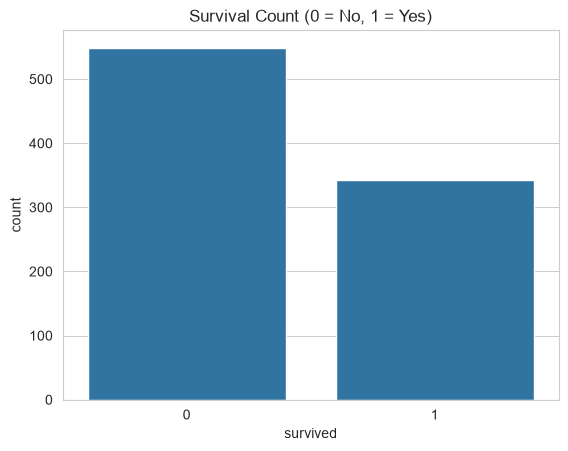

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


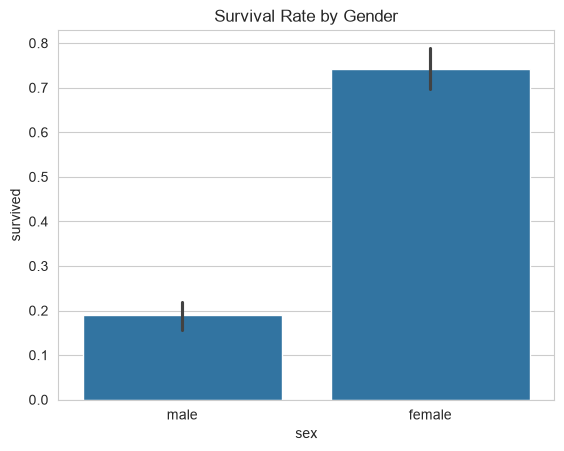

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


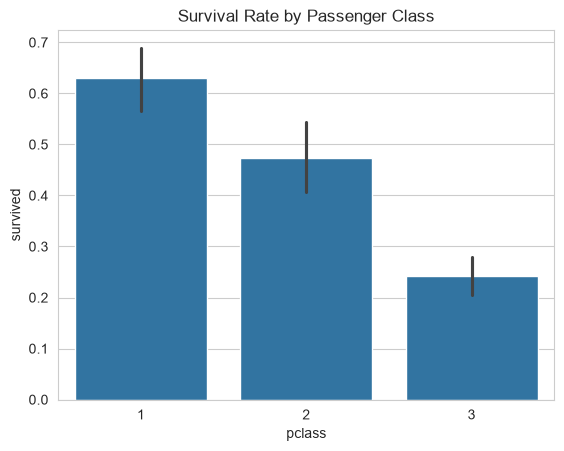

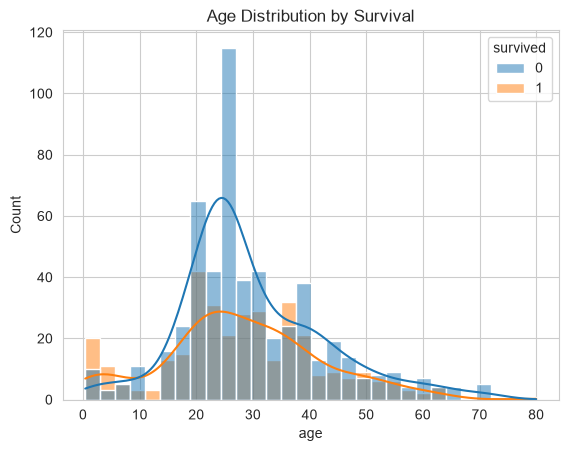

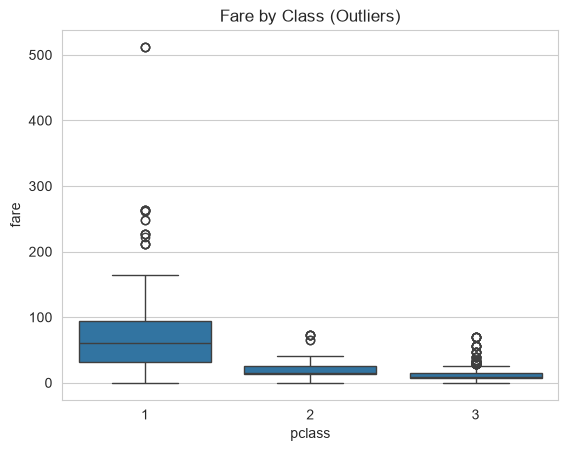

Fare outliers: 116
Max fare: 512.3292
survived    1.000000
pclass     -0.338481
age        -0.059576
sibsp      -0.035322
parch       0.081629
fare        0.257307
Name: survived, dtype: float64


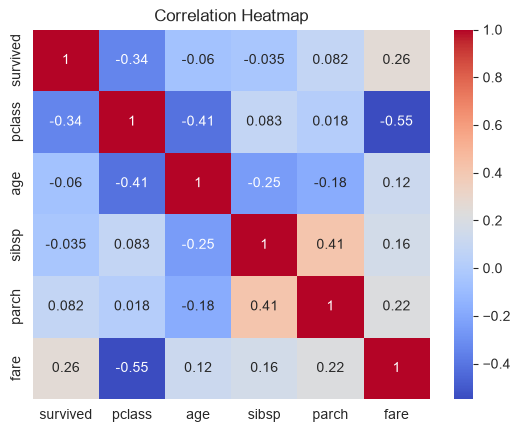

family_size
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: survived, dtype: float64


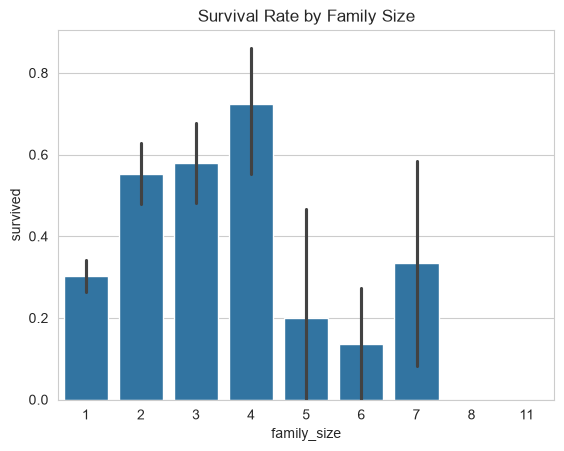

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")

# Load data
df = pd.read_csv("data/titanic_cleaned.csv")
df["survived"] = df["survived"].astype(int)
print(df.shape)
display(df.head())
display(df.describe())

# 1. Overall survival
print("Overall survival rate:", df["survived"].mean())
sns.countplot(x="survived", data=df)
plt.title("Survival Count (0 = No, 1 = Yes)")
plt.savefig("images/1_survival.png", bbox_inches="tight")
plt.show()

# 2. Gender
print(df.groupby("sex")["survived"].mean())
sns.barplot(x="sex", y="survived", data=df)
plt.title("Survival Rate by Gender")
plt.savefig("images/2_gender.png", bbox_inches="tight")
plt.show()

# 3. Class
print(df.groupby("pclass")["survived"].mean())
sns.barplot(x="pclass", y="survived", data=df)
plt.title("Survival Rate by Passenger Class")
plt.savefig("images/3_class.png", bbox_inches="tight")
plt.show()

# 4. Age
sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True)
plt.title("Age Distribution by Survival")
plt.savefig("images/4_age.png", bbox_inches="tight")
plt.show()

# 5. Fare outliers
sns.boxplot(x="pclass", y="fare", data=df)
plt.title("Fare by Class (Outliers)")
plt.savefig("images/5_fare_outliers.png", bbox_inches="tight")
plt.show()

q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
print("Fare outliers:", len(df[df["fare"] > q3 + 1.5 * iqr]))
print("Max fare:", df["fare"].max())

# 6. Heatmap
corr = df[["survived","pclass","age","sibsp","parch","fare"]].corr()
print(corr["survived"])
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("images/6_heatmap.png", bbox_inches="tight")
plt.show()

# 7. Family size
df["family_size"] = df["sibsp"] + df["parch"] + 1
print(df.groupby("family_size")["survived"].mean())
sns.barplot(x="family_size", y="survived", data=df)
plt.title("Survival Rate by Family Size")
plt.savefig("images/7_family.png", bbox_inches="tight")
plt.show()

Key Insights – Titanic Dataset
1. Passenger Class: First-class passengers had a higher survival rate (63%) than third-class passengers (24.2%). This shows that passenger class influenced survival chances.

2. Gender: Women had a much higher survival rate (74%) than men (19%). This supports the women-and-children-first evacuation rule.

3. Family Size: Passengers travelling in families of 2–4 had better survival rates (55–72%). Solo travellers and very large families had lower survival rates.

4. Fare Anomalies: The fare data contains 116 extreme outliers. The maximum fare was 512.33, while the median was only 14.45. This indicates a right-skewed distribution.

5. Age: Young children had better survival chances, while passengers aged 20–40 experienced more deaths than survivals.

6. Correlation: Survival had a negative correlation with passenger class (-0.34) and a positive correlation with fare (+0.26). This indicates that higher-class passengers and those paying higher fares generally had better survival chances.

Overall Conclusion
The Titanic analysis shows that gender, passenger class, family size, age, and ticket fare were important factors associated with passenger survival.